# Module 3: estimating cultivar coefficients (GLUE), soil data and water-limited production

This notebook follows the third day of a DSSAT training course:

1. estimate the coefficients of a soybean cultivar from field data with **GLUE**, ported to Python in
   `docs/notebooks/glue.py` from DSSAT's GLUE tool;
2. read and estimate **soil** water limits;
3. switch the **water balance** on and look at water-limited production: soil water in each layer,
   the soil's capacity to store water, and automatic irrigation.

**Data.** Soybean experiments IUAM8801, IUAM9001, OHWO8801, OHWO9001 and UFGA7902 (Williams-82; the
course's GLUE exercise) and IUAM9701, IUAM9702 for an independent check; peanut UFGA8401; maize UFGA8201 and
the soil file, all from [DSSAT/dssat-csm-data](https://github.com/DSSAT/dssat-csm-data) (BSD-3) at a pinned
commit. From the course data (`notebooks/course-data/`): the Colorado maize experiments of GLUE self test 4 and the
Umariya and Orangeburg soil sheets. GLUE follows [DSSAT/glue](https://github.com/DSSAT/glue) (BSD-3) at
commit e86093e.

**Needs.** As in modules 1 and 2. The GLUE part runs about 36,000 soybean seasons; on a many-core machine
that takes a few minutes (it runs up to 99 parameter sets per experiment file and many files at once).

In [1]:
import sys, time, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))      # docs/notebooks
import learnlib as L
import glue as G
from sol import read_sol, write_sol, SoilProfile
from soils import saxton_rawls
from wth import read_wth

M = "module3"
WORKERS = max(4, min(48, (os.cpu_count() or 8) - 2))
print("engine   :", L.config.engine_exe())
print("csm-data :", L.CSM_DATA, "@", L.CSM_DATA_COMMIT[:8])
print("GLUE     :", G.glue_url("Calculation.r"))
print("workers  :", WORKERS)

engine   : C:\TEMP\dsn\dssat\dscsm048.exe
csm-data : C:\Users\benny\OneDrive\Documents\Github\dssat-csm-data @ 99c95b34
GLUE     : https://github.com/DSSAT/glue/blob/e86093e400fbbdfc8e2c751c98acc2136835c3af/Calculation.r
workers  : 48


## 1. Estimating cultivar coefficients with GLUE

### The observations

The five treatments the course's GLUE exercise selects for Williams-82 soybean (a maturity group 3
cultivar) are used for calibration: treatment 1 of IUAM8801, IUAM9001, OHWO8801 and OHWO9001, and the fully
irrigated treatment 4 of UFGA7902. Two more
(IUAM9701 and IUAM9702) are kept back to test the result: only their yield was measured.

In [2]:
def exp_spec(e, soil, trno=1, wth=None):
    return {"exp": e, "ext": ".SBX", "files": [f"Soybean/{e}.SBX", f"Weather/{wth or e}.WTH", "Soil/SOIL.SOL"],
            "filea": f"Soybean/{e}.SBA", "soil": soil, "trno": trno}

CAL = [exp_spec("IUAM8801", "IBSB910049"), exp_spec("IUAM9001", "IBSB910049"),
       exp_spec("OHWO8801", "IBSB910046"), exp_spec("OHWO9001", "IBSB910064"),
       exp_spec("UFGA7902", "IBSB910015", trno=4, wth="UFGA7901")]
VAL = [exp_spec("IUAM9701", "IUBF970110", 2), exp_spec("IUAM9702", "IUBF970211", 2)]
obs = G.observed(CAL)
obs_val = G.observed(VAL)
obs

,exp,ADAP,MDAP,HWAM,CWAM,PWAM,LAIX,HWUM
0,IUAM8801,51.0,129,2368.0,6117.0,3604.0,5.57,0.1270
1,IUAM9001,66.0,139,3168.0,6674.0,4552.0,6.29,0.1682
2,OHWO8801,71.0,145,3976.0,8090.0,5194.0,7.65,0.1510
3,OHWO9001,NaN,150,3149.0,7113.0,4915.0,7.21,0.1640
4,UFGA7902,38.0,93,2474.0,3893.0,NaN,3.15,0.1750


### Priors: what may each coefficient be?

GLUE starts from a range for every coefficient. DSSAT keeps them in the cultivar file itself: a `MINIMA` and
a `MAXIMA` row, and a `!Calibration` row that flags each coefficient as **P** (phenology), **G** (growth) or
**N** (not calibrated). GLUE draws parameter sets uniformly within the ranges
([`Uniform.r`](https://github.com/DSSAT/glue/blob/e86093e400fbbdfc8e2c751c98acc2136835c3af/Uniform.r)).

In [3]:
rng = G.ranges("SBGRO048", "IB0010")
rng["outside_range"] = (rng["default"] < rng["min"]) | (rng["default"] > rng["max"])
rng

,coef,flag,min,max,default,outside_range
0,CSDL,P,11.780,14.600,13.400,False
1,PPSEN,P,0.129,0.385,0.285,False
2,EM-FL,P,9.000,28.900,19.000,False
3,FL-SH,N,5.000,10.000,8.300,False
4,FL-SD,P,11.000,22.000,14.200,False
5,SD-PM,P,22.000,37.700,32.200,False
6,FL-LF,N,18.000,26.000,28.000,True
7,LFMAX,G,1.000,1.400,0.970,True
8,SLAVR,G,300.000,400.000,385.000,False
9,SIZLF,G,137.000,230.000,180.000,False


### The likelihood

For each measurement GLUE computes how likely the simulated value is if the measurement has a normal error,
`exp(-(M - S)^2 / (2 var)) / sqrt(2 pi var)`
([`Calculation.r`](https://github.com/DSSAT/glue/blob/e86093e400fbbdfc8e2c751c98acc2136835c3af/Calculation.r)).
The variances are fixed in
[`MeasurementVariance_All.csv`](https://github.com/DSSAT/glue/blob/e86093e400fbbdfc8e2c751c98acc2136835c3af/MeasurementVariance_All.csv):
a standard deviation of 3 days for anthesis and 7 days for maturity, and a coefficient of variation for
weights (0.3 for yields and tops, 0.1 for seed size, 0.4 for LAI). Likelihoods are multiplied over the
measurements of an experiment, normalised over the parameter sets, multiplied over the experiments and
normalised again. Round 1 fits the phenology coefficients to the dates; round 2 keeps the best round-1
values and fits the growth coefficients to the weights.

In [4]:
pd.DataFrame([{"measurement": k, "kind": v[0], "value": v[1], "round": v[2]} for k, v in G.VARIANCE.items()])

,measurement,kind,value,round
0,ADAP,sd,3.0,1
1,MDAP,sd,7.0,1
2,PWAM,cv,0.3,2
3,HWAM,cv,0.3,2
4,CWAM,cv,0.3,2
5,LAIX,cv,0.4,2
6,HWUM,cv,0.1,2


### Before calibration

Williams-82 as it is in the engine's cultivar file:

In [5]:
default = G.sample(rng, 1, 1).iloc[:1].copy()
for _, r in rng.iterrows():
    default[r.coef] = r["default"]
sim0 = G.run_sets(CAL + VAL, default, "IB0010", "SBGRO048", "def", workers=WORKERS)
sim0

,set,exp,ADAP,MDAP,HWAM,CWAM,PWAM,LAIX,HWUM
0,1,IUAM8801,58,125,2817,6341,3659,5.711085,0.157695
1,1,IUAM9001,63,133,3700,7450,4998,6.066354,0.149194
2,1,OHWO8801,76,142,3620,7491,4938,6.639524,0.155467
3,1,OHWO9001,75,145,3541,7185,4822,6.609224,0.149739
4,1,UFGA7902,39,97,2772,4422,3922,2.832199,0.145784
5,1,IUAM9701,63,131,3767,8219,5249,7.236816,0.149195
6,1,IUAM9702,65,135,3084,6676,4178,6.818458,0.152660


### Round 1: phenology

In [6]:
N = int(os.environ.get("XLEARN_GLUE_N", 3000))     # sets per round
t0 = time.time()
sets1 = G.sample(rng, N, 1, seed=2018)
sim1 = G.run_sets(CAL, sets1, "IB0010", "SBGRO048", "r1", workers=WORKERS)
lik1 = G.likelihood(sim1, obs, 1)
P = list(rng[rng.flag == "P"].coef)
post1 = G.posterior_summary(sets1, lik1, P)
print(f"round 1: {len(sim1)} seasons in {time.time() - t0:.0f} s; sets that matured everywhere: "
      f"{int(sim1.groupby('set').MDAP.apply(lambda s: s.notna().all()).sum())} of {N}")
post1

round 1: 15000 seasons in 264 s; sets that matured everywhere: 2086 of 3000


,coef,best,mean,sd,prior_min,prior_max
0,CSDL,13.249898,13.255926,0.456622,11.781553,14.599494
1,PPSEN,0.267109,0.275741,0.061453,0.129002,0.384951
2,EM-FL,17.393830,17.718176,1.703780,9.000204,28.895782
3,FL-SD,11.895984,17.096515,3.242615,11.001382,21.995934
4,SD-PM,37.552135,31.146929,3.913858,22.002702,37.697495


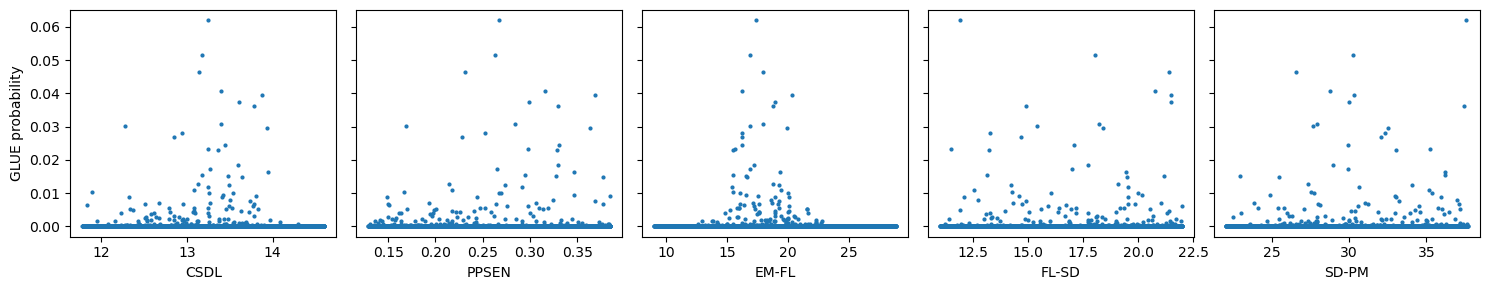

In [7]:
t1 = sets1.merge(lik1[["set", "prob"]], on="set")
fig, axs = plt.subplots(1, len(P), figsize=(15, 3), sharey=True)
for ax, c in zip(axs, P):
    ax.scatter(t1[c], t1.prob, s=4); ax.set_xlabel(c)
axs[0].set_ylabel("GLUE probability")
plt.tight_layout()

### Round 2: growth

In [8]:
best1 = post1.set_index("coef")["best"].to_dict()
t0 = time.time()
sets2 = G.sample(rng, N, 2, fixed=best1, seed=2019)
sim2 = G.run_sets(CAL, sets2, "IB0010", "SBGRO048", "r2", workers=WORKERS)
lik2 = G.likelihood(sim2, obs, 2)
Gc = list(rng[rng.flag == "G"].coef)
post2 = G.posterior_summary(sets2, lik2, Gc)
print(f"round 2: {len(sim2)} seasons in {time.time() - t0:.0f} s")
post2

round 2: 15000 seasons in 250 s


,coef,best,mean,sd,prior_min,prior_max
0,LFMAX,1.032143,1.104075,0.085230,1.000186,1.399889
1,SLAVR,396.348431,359.079587,26.647380,300.076718,399.998198
2,SIZLF,175.967169,178.767408,24.894066,137.018047,229.953704
3,WTPSD,0.151384,0.155078,0.004139,0.150003,0.189991
4,SFDUR,20.764567,21.640275,2.154208,17.000121,25.496115
5,SDPDV,2.363773,2.057482,0.208301,1.700413,2.439995


### Best values on the edge of their range

A best value that sits on the edge of its prior range says the data want a value the range does not
allow. Here that happens in round 2, and the engine's own Williams-82 values for `LFMAX` and `SFDUR` already lie
outside the ranges of the cultivar file. Round 2 is run again with the ranges of those coefficients widened
by half their width on the side that was hit:

In [9]:
edge = []
rng_wide = rng.copy()
for _, r in post2.iterrows():
    lo, hi = rng.loc[rng.coef == r.coef, ["min", "max"]].iloc[0]
    w = hi - lo
    side = "min" if r.best - lo < 0.05 * w else "max" if hi - r.best < 0.05 * w else None
    if side:
        new = max(lo - 0.5 * w, 0.0) if side == "min" else hi + 0.5 * w
        rng_wide.loc[rng_wide.coef == r.coef, side] = new
        edge.append({"coef": r.coef, "best": r.best, "side": side, "old_min": lo, "old_max": hi,
                     "new_min": rng_wide.loc[rng_wide.coef == r.coef, "min"].iloc[0],
                     "new_max": rng_wide.loc[rng_wide.coef == r.coef, "max"].iloc[0]})
edge = pd.DataFrame(edge)
t0 = time.time()
sets3 = G.sample(rng_wide, N, 2, fixed=best1, seed=2020)
sim3 = G.run_sets(CAL, sets3, "IB0010", "SBGRO048", "r3", workers=WORKERS)
lik3 = G.likelihood(sim3, obs, 2)
post3 = G.posterior_summary(sets3, lik3, Gc)
print(f"round 2, wider ranges: {len(sim3)} seasons in {time.time() - t0:.0f} s")
display(edge); post3

round 2, wider ranges: 15000 seasons in 271 s


,coef,best,side,old_min,old_max,new_min,new_max
0,SLAVR,396.348431,max,300.00,400.00,300.00,450.00
1,WTPSD,0.151384,min,0.15,0.19,0.13,0.19


,coef,best,mean,sd,prior_min,prior_max
0,LFMAX,1.020757,1.106673,0.089082,1.000264,1.399933
1,SLAVR,436.675873,387.829469,39.393867,300.099944,449.890096
2,SIZLF,174.747192,176.937396,24.665975,137.001935,229.961366
3,WTPSD,0.146365,0.147339,0.007548,0.130023,0.189992
4,SFDUR,21.500243,20.678409,2.180812,17.000519,25.498369
5,SDPDV,1.728097,2.062645,0.210283,1.700155,2.439532


### After calibration, and the independent check

In [10]:
best = default.copy()
for c, v in {**best1, **post2.set_index("coef")["best"].to_dict()}.items():
    best[c] = v
best["set"] = 2
best3 = best.copy()
for c, v in post3.set_index("coef")["best"].to_dict().items():
    best3[c] = v
best3["set"] = 3
both = pd.concat([default.assign(set=1), best, best3])
sim_eval = G.run_sets(CAL + VAL, both, "IB0010", "SBGRO048", "eval", workers=WORKERS)
sim_eval["version"] = sim_eval.set.map({1: "default", 2: "GLUE", 3: "GLUE, wider ranges"})
ob = pd.concat([obs.assign(use="calibration"), obs_val.assign(use="independent check")])
long = []
for v in ["ADAP", "MDAP", "HWAM", "CWAM", "PWAM", "LAIX", "HWUM"]:
    for _, r in sim_eval.iterrows():
        o = ob[ob.exp == r.exp].iloc[0]
        long.append({"exp": r.exp, "use": o.use, "version": r.version, "variable": v, "simulated": r[v], "observed": o[v]})
evals = pd.DataFrame(long).dropna(subset=["observed"])
stat = (evals.groupby(["variable", "version"])
        .apply(lambda g: pd.Series({"n": len(g), "rmse": L.rmse(g.observed, g.simulated), "d": L.willmott_d(g.observed, g.simulated)}))
        .reset_index())
stat.pivot(index="variable", columns="version", values="rmse").round(2)

version,GLUE,"GLUE, wider ranges",default
variable,,,
ADAP,3.50,3.50,4.58
CWAM,573.07,485.88,509.15
HWAM,504.77,494.17,476.82
HWUM,0.01,0.02,0.02
LAIX,0.55,0.47,0.56
MDAP,3.55,3.55,4.52
PWAM,470.52,483.59,262.74


In [11]:
L.export(obs.assign(use="calibration"), M, "glue_obs")
L.export(rng, M, "glue_ranges", 4)
L.export(t1[["set", "prob"] + P], M, "glue_round1", 5)
L.export(sets2.merge(lik2[["set", "prob"]], on="set")[["set", "prob"] + Gc], M, "glue_round2", 5)
L.export(sets3.merge(lik3[["set", "prob"]], on="set")[["set", "prob"] + Gc], M, "glue_round2_wide", 5)
L.export(pd.concat([post1.assign(round="1"), post2.assign(round="2"), post3.assign(round="2, wider ranges")]), M, "glue_posterior", 4)
L.export(edge, M, "glue_widened", 4)
L.export(evals, M, "glue_eval", 4)
L.export(stat, M, "glue_stats", 4)
L.export(pd.DataFrame([{"sets_per_round": N, "seasons": len(sim1) + len(sim2) + len(sim3), "workers": WORKERS}]), M, "glue_info")

WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module3/glue_info.csv')

### GLUE self test 4: a new maize cultivar from Colorado

The course's last GLUE exercise calibrates a cultivar that is not yet in DSSAT: the maize hybrid DEKALB
52-59 AF, grown at Greeley, Colorado, in 2008 and 2010 with full irrigation and with 40% of it
(Anothai et al. 2013). The experiment files, weather and soil file come with the course
(`course-data/colorado/`). The exercise asks for a new cultivar entry `CO0801` built from an existing variety;
the notebook uses DEKALB 485 (`IB1072`) of the engine's cultivar file as that starting point. All four
treatments are used; their FileA has anthesis, maturity, yield and tops weight.

In [12]:
def co_spec(exp, trno, soil):
    return {"id": f"{exp}-T{trno}", "exp": exp, "ext": ".MZX", "source": "course", "trno": trno, "soil": soil,
            "files": [f"colorado/{exp}.MZX", f"colorado/{exp}.WTH", "colorado/GR.SOL"], "filea": f"colorado/{exp}.MZA",
            "sim_overrides": {"NREPS": 1}}

CO = [co_spec("GRCO0801", 1, "GRWD080011"), co_spec("GRCO0801", 2, "GRWD080016"),
      co_spec("GRCO1001", 1, "GRWD100011"), co_spec("GRCO1001", 2, "GRWD100016")]
for e in CO:
    e["files"][-1] = "colorado/GR.SOL"
obs_co = G.observed(CO)
rng_co = G.ranges("MZCER048", "IB1072")
display(obs_co, rng_co)

,exp,ADAP,MDAP,HWAM,CWAM,PWAM,LAIX,HWUM
0,GRCO0801-T1,86,150,13228.0,22112.0,NaN,NaN,NaN
1,GRCO0801-T2,86,150,8824.0,14331.0,NaN,NaN,NaN
2,GRCO1001-T1,81,136,11168.0,18881.0,NaN,NaN,NaN
3,GRCO1001-T2,81,136,5505.0,9294.0,NaN,NaN,NaN


,coef,flag,min,max,default
0,P1,P,5.0,450.0,215.0
1,P2,P,0.0,2.0,0.6
2,P5,P,580.0,999.0,785.0
3,G2,G,248.0,990.0,750.0
4,G3,G,5.0,16.5,8.7
5,PHINT,N,38.0,75.0,45.0


In [13]:
# GR.SOL holds the soils; the engine looks for the soil file named after the first two letters of the ID
# (GR.SOL for GRWD...), so it is staged under that name.
t0 = time.time()
co_default = G.sample(rng_co, 1, 1).iloc[:1].copy()
for _, r in rng_co.iterrows():
    co_default[r.coef] = r["default"]
NCO = int(os.environ.get("XLEARN_GLUE_N", 2000))
co1 = G.sample(rng_co, NCO, 1, seed=52)
sim_co1 = G.run_sets(CO, co1, "IB1072", "MZCER048", "co1", workers=WORKERS)
lik_co1 = G.likelihood(sim_co1, obs_co, 1)
Pm = list(rng_co[rng_co.flag == "P"].coef)
post_co1 = G.posterior_summary(co1, lik_co1, Pm)
co2 = G.sample(rng_co, NCO, 2, fixed=post_co1.set_index("coef")["best"].to_dict(), seed=59)
sim_co2 = G.run_sets(CO, co2, "IB1072", "MZCER048", "co2", workers=WORKERS)
lik_co2 = G.likelihood(sim_co2, obs_co, 2)
Gm = list(rng_co[rng_co.flag == "G"].coef)
post_co2 = G.posterior_summary(co2, lik_co2, Gm)
best_co = co_default.copy()
for c, v in {**post_co1.set_index("coef")["best"].to_dict(), **post_co2.set_index("coef")["best"].to_dict()}.items():
    best_co[c] = v
both_co = pd.concat([co_default.assign(set=1), best_co.assign(set=2)])
sim_co = G.run_sets(CO, both_co, "IB1072", "MZCER048", "coev", workers=WORKERS)
sim_co["version"] = sim_co.set.map({1: "DEKALB 485 as it is", 2: "GLUE: CO0801"})
print(f"Colorado GLUE: {len(sim_co1) + len(sim_co2)} seasons in {time.time() - t0:.0f} s")
co_eval = []
for v in ["ADAP", "MDAP", "HWAM", "CWAM"]:
    for _, r in sim_co.iterrows():
        o = obs_co[obs_co.exp == r.exp].iloc[0]
        co_eval.append({"exp": r.exp, "version": r.version, "variable": v, "simulated": r[v], "observed": o[v]})
co_eval = pd.DataFrame(co_eval)
co_cul = pd.concat([post_co1.assign(round="1"), post_co2.assign(round="2")])
co_cul["DEKALB 485"] = co_cul.coef.map(rng_co.set_index("coef")["default"])
display(co_cul)
co_eval.pivot_table(index=["exp", "variable"], columns="version", values="simulated").join(co_eval.groupby(["exp", "variable"])["observed"].first())

Colorado GLUE: 16000 seasons in 168 s


,coef,best,mean,sd,prior_min,prior_max,round,DEKALB 485
0,P1,247.395667,244.454392,22.123239,5.031595,449.343032,1,215.0
1,P2,1.237487,1.242804,0.503020,0.000625,1.997433,1,0.6
2,P5,608.446720,628.558692,34.777022,580.181616,998.953208,1,785.0
0,G2,573.037012,677.914586,195.344033,248.026413,989.798979,2,750.0
1,G3,11.836032,11.985038,2.768234,5.003465,16.492472,2,8.7


DEKALB 485 as it is  GLUE: CO0801  observed
exp         variable                                             
GRCO0801-T1 ADAP                     75.0          84.0      86.0
            CWAM                  26978.0       25165.0   22112.0
            HWAM                  16006.0       11103.0   13228.0
            MDAP                    151.0         151.0     150.0
GRCO0801-T2 ADAP                     75.0          84.0      86.0
            CWAM                  13282.0       15932.0   14331.0
            HWAM                   7845.0        8518.0    8824.0
            MDAP                    151.0         151.0     150.0
GRCO1001-T1 ADAP                     75.0          82.0      81.0
            CWAM                  24409.0       23865.0   18881.0
            HWAM                  12022.0        9650.0   11168.0
            MDAP                    138.0         132.0     136.0
GRCO1001-T2 ADAP                     75.0          82.0      81.0
            CWAM                  12606.0       13213.0    9294.0
            HWAM                   5577.0        5281.0    5505.0
            MDAP                    138.0         132.0     136.0

In [14]:
L.export(obs_co, M, "co_obs"); L.export(co_cul, M, "co_posterior", 4); L.export(co_eval, M, "co_eval", 4)
L.export(co1.merge(lik_co1[["set", "prob"]], on="set")[["set", "prob"] + Pm], M, "co_round1", 5)
L.export(co2.merge(lik_co2[["set", "prob"]], on="set")[["set", "prob"] + Gm], M, "co_round2", 5)

WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module3/co_round2.csv')

### Calibration with in-season data: peanut UFGA8401

The course's second calibration exercise works by hand, one coefficient at a time, against growth analysis
data taken during the season: the irrigated treatment of the 1984 Florunner peanut experiment UFGA8401. It
asks for four statistics of four variables (tops weight, seed weight, seed number and pod harvest index): the
RMSE, the intercept `a` and slope `b` of the regression of simulated on observed values, and Willmott's `d`.
The suggested coefficients: `LFMAX` (the size of tops and seed weight), `FL-SH` and `FL-SD` moved together
(the timing of seed growth), `PODUR` (the first rise of seed number and pod harvest index) and `XFRT` (the
share of growth going to pods and seeds).

Instead of one run at a time, the notebook runs a grid of all four, so the page can move each one freely.

In [15]:
EXPP = "UFGA8401"
fxp = L.filex.FileX.read(L.CSM_DATA / f"Peanut/{EXPP}.PNX")
trp = fxp.treatments()
print(trp[["TNAME", "CU", "MI"]])
culp = L.cultivar_table("PNGRO048")
cu_line = next(l for l in (L.CSM_DATA / f"Peanut/{EXPP}.PNX").read_text(encoding="latin-1").splitlines() if l.startswith(" 1 PN "))
pn_cul = cu_line.split()[2]
pn_base = culp[culp["var"] == pn_cul].iloc[0]
print("cultivar", pn_cul, pn_base["name"], {c: pn_base[c] for c in ["LFMAX", "FL-SH", "FL-SD", "PODUR", "XFRT"]})
obsTp = L.read_filet(L.CSM_DATA / f"Peanut/{EXPP}.PNT")
obsTp = obsTp[obsTp.TRNO == 1]
print("observed variables:", [c for c in ["CWAD", "GWAD", "G#AD", "HIPD"] if c in obsTp.columns], len(obsTp), "dates")

                     TNAME  CU  MI
N                                 
1                IRRIGATED   1   1
2  RAINFED, EXCEPT IRRIGAT   1   2


cultivar IB0002 FLORUNNER {'LFMAX': np.float64(1.4), 'FL-SH': np.float64(9.2), 'FL-SD': np.float64(18.8), 'PODUR': np.float64(24.0), 'XFRT': np.float64(0.92)}
observed variables: ['CWAD', 'GWAD', 'G#AD', 'HIPD'] 19 dates


In [16]:
from itertools import product
lf = [round(pn_base["LFMAX"] * f, 3) for f in (0.85, 0.925, 1.0, 1.075, 1.15)]
shift = [-4.0, -2.0, 0.0, 2.0, 4.0]
podur = [round(pn_base["PODUR"] * f, 1) for f in (0.7, 0.85, 1.0, 1.15, 1.3)]
xfrt = [round(min(1.0, pn_base["XFRT"] * f), 2) for f in (0.9, 1.0)] + ([1.0] if pn_base["XFRT"] < 1.0 else [])
xfrt = sorted(set(xfrt))
grid = pd.DataFrame(list(product(lf, shift, podur, xfrt)), columns=["LFMAX", "shift", "PODUR", "XFRT"])
grid["FL-SH"] = (pn_base["FL-SH"] + grid["shift"]).round(1)
grid["FL-SD"] = (pn_base["FL-SD"] + grid["shift"]).round(1)
grid["set"] = range(1, len(grid) + 1)
print(len(grid), "combinations; XFRT values", xfrt)
pdate_p = pd.Timestamp(fxp.planting_date(int(trp.loc[1, "MP"])))

def run_grid_chunk(k, part):
    d = L.work_dir(f"m3_pn_{k:03d}")
    L.stage(d, f"Weather/{EXPP}.WTH", "Soil/SOIL.SOL")
    codes = {f"PG{int(r.set):04d}": r for r in part.itertuples()}
    L.write_cultivar_variants(d, pn_cul, {c: {"LFMAX": r.LFMAX, "FL-SH": r._5, "FL-SD": r._6, "PODUR": r.PODUR, "XFRT": r.XFRT}
                                          for c, r in codes.items()}, "PNGRO048")
    u = pd.DataFrame({"cell": list(codes), "name": list(codes), "wsta": "UFGA", "soil_id": None, "pdate": pdate_p,
                      "trno_template": 1, "CU.INGENO": list(codes)})
    u["soil_id"] = next(l for l in fxp.blocks("FL")[1] if l[:2].strip() == "1" and not l.startswith("@"))[-30:].split()[0] if False else SOILP
    name, u = L.write_built(d, fxp, u, "UFGA8491", ".PNX", title="In-season calibration grid")
    s, dd, _ = L.run(d, name)
    g = dd["plantgro"][["TRNO", "DAP", "date", "CWAD", "GWAD", "G#AD", "HIPD"]].merge(u[["TRNO", "CU.INGENO"]], on="TRNO")
    g["set"] = g["CU.INGENO"].str[2:].astype(int)
    return g.drop(columns=["TRNO", "CU.INGENO"])

SOILP = next(l.split()[-2] for l in (L.CSM_DATA / f"Peanut/{EXPP}.PNX").read_text(encoding="latin-1").splitlines()
             if l.startswith(" 1 ") and "UFGA" in l and len(l.split()) > 9)
print("soil", SOILP)
from concurrent.futures import ThreadPoolExecutor
t0 = time.time()
parts = [grid.iloc[i:i + 99] for i in range(0, len(grid), 99)]
with ThreadPoolExecutor(len(parts)) as ex:
    pn_daily = pd.concat(ex.map(run_grid_chunk, range(len(parts)), parts), ignore_index=True)
print(f"{len(grid)} peanut seasons with daily output in {time.time() - t0:.0f} s")

375 combinations; XFRT values [np.float64(0.83), np.float64(0.92), 1.0]
soil IBPN910015


375 peanut seasons with daily output in 31 s


In [17]:
def regab(o, s):
    o, s = np.asarray(o, float), np.asarray(s, float)
    b, a = np.polyfit(o, s, 1) if len(o) > 2 else (np.nan, np.nan)
    return a, b

VARS = ["CWAD", "GWAD", "G#AD", "HIPD"]
obs_long = obsTp[["date"] + [v for v in VARS if v in obsTp.columns]].melt(id_vars="date", var_name="variable", value_name="observed").dropna()
pn_stats = []
for sid, g in pn_daily.groupby("set"):
    gi = g.set_index("date")
    for v, o in obs_long.groupby("variable"):
        o = o[o.date.isin(gi.index)]
        sv = gi.loc[o.date, v].astype(float).values
        a, b = regab(o.observed, sv)
        pn_stats.append({"set": sid, "variable": v, "n": len(o), "rmse": L.rmse(o.observed, sv), "a": a, "b": b,
                         "d": L.willmott_d(o.observed, sv)})
pn_stats = pd.DataFrame(pn_stats).merge(grid, on="set")
base_set = int(grid[(grid.LFMAX == lf[2]) & (grid["shift"] == 0) & (grid.PODUR == podur[2]) & (grid.XFRT == round(pn_base["XFRT"], 2))].set.iloc[0])
mean_d = pn_stats.groupby("set").d.mean()
best_set = int(mean_d.idxmax())
print("Florunner as it is: set", base_set, "mean d", round(mean_d[base_set], 3), "| best mean d: set", best_set, round(mean_d[best_set], 3))
pn_stats[pn_stats.set.isin([base_set, best_set])].round(3)

Florunner as it is: set 188 mean d 0.979 | best mean d: set 324 0.988


,set,variable,n,rmse,a,b,d,LFMAX,shift,PODUR,XFRT,FL-SH,FL-SD
748,188,CWAD,19,1285.118,-332.731,0.893,0.976,1.40,0.0,24.0,0.92,9.2,18.8
749,188,G#AD,19,112.553,-0.454,0.837,0.972,1.40,0.0,24.0,0.92,9.2,18.8
750,188,GWAD,19,590.725,-96.562,0.849,0.974,1.40,0.0,24.0,0.92,9.2,18.8
751,188,HIPD,19,0.034,-0.012,0.987,0.993,1.40,0.0,24.0,0.92,9.2,18.8
1292,324,CWAD,19,1130.797,-254.886,0.906,0.982,1.61,-2.0,24.0,1.00,7.2,16.8
1293,324,G#AD,19,80.448,8.530,0.918,0.987,1.61,-2.0,24.0,1.00,7.2,16.8
1294,324,GWAD,19,402.287,-73.019,0.933,0.989,1.61,-2.0,24.0,1.00,7.2,16.8
1295,324,HIPD,19,0.033,-0.007,1.060,0.994,1.61,-2.0,24.0,1.00,7.2,16.8


In [18]:
pdays = pn_daily[(pn_daily.DAP % 4 == 0) | pn_daily.date.isin(obs_long.date)].drop(columns="date")
obs_out = obsTp[["date"] + [v for v in VARS if v in obsTp.columns]].copy()
obs_out["DAP"] = (obs_out.date - pdate_p).dt.days
L.export(grid.drop(columns="shift").assign(shift=grid["shift"]), M, "pn_grid", 4)
L.export(pdays, M, "pn_daily", 3)
L.export(pn_stats[["set", "variable", "n", "rmse", "a", "b", "d"]], M, "pn_stats", 4)
L.export(obs_out, M, "pn_obs", 4)
L.export(pd.DataFrame([{"cultivar": pn_cul, "name": pn_base["name"], "base_set": base_set, "best_set": best_set,
                        **{c: pn_base[c] for c in ["LFMAX", "FL-SH", "FL-SD", "PODUR", "XFRT"]}}]), M, "pn_info", 4)

WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module3/pn_info.csv')

## 2. Soil data

A DSSAT soil profile lists layers with their lower limit of plant-extractable water (`SLLL`, the wilting
point), drained upper limit (`SDUL`, field capacity), saturation (`SSAT`), a root growth factor (`SRGF`),
texture and organic carbon. The water a soil can hold for the crop is the sum over layers of
`(SDUL - SLLL) x layer thickness`. The soil file of DSSAT has twelve generic profiles (three depths of
four textures) and the measured Millhopper fine sand of the maize experiment:

In [19]:
ids = [f"IB{i:08d}" for i in range(1, 13)] + ["IBMZ910014"]
profiles = read_sol(L.CSM_DATA / "Soil/SOIL.SOL", ids=ids + ["IBSB910017"])

def layer_table(p):
    lay = p.layers.copy()
    lay["top"] = np.r_[0, lay.SLB.values[:-1]]
    lay["thick"] = lay.SLB - lay.top
    return lay

rows, paw = [], []
for sid, p in profiles.items():
    lay = layer_table(p)
    for _, r in lay.iterrows():
        rows.append({"id": sid, "name": p.description, "top": r.top, "bottom": r.SLB, "LL": r.SLLL, "DUL": r.SDUL,
                     "SAT": r.SSAT, "SRGF": r.SRGF, "clay": r.SLCL, "silt": r.SLSI, "OC": r.SLOC, "BD": r.SBDM})
    paw.append({"id": sid, "name": p.description.strip(), "texture": p.texture, "depth_cm": float(lay.SLB.max()),
                "paw_mm": float(((lay.SDUL - lay.SLLL) * lay.thick * 10).sum()), "source": "SOIL.SOL"})
layers = pd.DataFrame(rows)
paw = pd.DataFrame(paw)
paw

,id,name,texture,depth_cm,paw_mm,source
0,IB00000001,DEFAULT - DEEP SILTY CLAY,SIC,210.0,276.60,SOIL.SOL
1,IB00000002,DEFAULT - MEDIUM SILTY CLAY,SIC,150.0,211.80,SOIL.SOL
2,IB00000003,DEFAULT - SHALLOW SILTY CLAY,SIC,60.0,94.20,SOIL.SOL
3,IB00000004,DEFAULT - DEEP SILTY LOAM,SIL,210.0,200.55,SOIL.SOL
4,IB00000005,DEFAULT - MEDIUM SILTY LOAM,SIL,150.0,139.35,SOIL.SOL
5,IB00000006,DEFAULT - SHALLOW SILTY LOAM,SIL,60.0,60.45,SOIL.SOL
6,IB00000007,DEFAULT - DEEP SANDY LOAM,SL,210.0,229.20,SOIL.SOL
7,IB00000008,DEFAULT - MEDIUM SANDY LOAM,SL,150.0,165.60,SOIL.SOL
8,IB00000009,DEFAULT - SHALLOW SANDY LOAM,SL,60.0,72.90,SOIL.SOL
9,IB00000010,DEFAULT - DEEP SAND,S,210.0,151.35,SOIL.SOL


### Estimating water limits from texture

When only texture and organic matter are known, a pedotransfer function estimates the limits. xdssat uses
Saxton and Rawls (2006) (`src/soils.py`); DSSAT's SBuild tool uses a Saxton and Rawls based method too
(Gijsman et al. 2002, as the course exercise says). Applied to the layers above (organic matter taken as 1.724 x
organic carbon):

In [20]:
ok = layers[(layers.clay >= 0) & (layers.silt >= 0) & (layers.OC >= 0) & layers.id.isin(ids)].copy()
sand = (100 - ok.clay - ok.silt) / 100
ll, dul, sat, ks = saxton_rawls(sand, ok.clay / 100, 1.724 * ok.OC)
ok["LL_sr"], ok["DUL_sr"], ok["SAT_sr"] = ll, dul, sat
sr = ok[["id", "name", "bottom", "clay", "silt", "OC", "LL", "LL_sr", "DUL", "DUL_sr", "SAT", "SAT_sr"]]
print("RMSE LL, DUL, SAT:", [round(L.rmse(sr[a], sr[a + "_sr"]), 3) for a in ["LL", "DUL", "SAT"]])
sr.head(12)

RMSE LL, DUL, SAT: [0.037, 0.045, 0.059]


,id,name,bottom,clay,silt,OC,LL,LL_sr,DUL,DUL_sr,SAT,SAT_sr
0,IB00000001,DEFAULT - DEEP SILTY CLAY,5.0,50.0,45.0,1.75,0.228,0.292640,0.385,0.422030,0.481,0.544967
1,IB00000001,DEFAULT - DEEP SILTY CLAY,15.0,50.0,45.0,1.75,0.228,0.292640,0.385,0.422030,0.481,0.544967
2,IB00000001,DEFAULT - DEEP SILTY CLAY,30.0,50.0,45.0,1.60,0.249,0.292714,0.406,0.422954,0.482,0.542675
3,IB00000001,DEFAULT - DEEP SILTY CLAY,45.0,50.0,45.0,1.45,0.249,0.292788,0.406,0.423878,0.465,0.540385
4,IB00000001,DEFAULT - DEEP SILTY CLAY,60.0,50.0,45.0,1.45,0.249,0.292788,0.406,0.423878,0.465,0.540385
5,IB00000001,DEFAULT - DEEP SILTY CLAY,90.0,50.0,45.0,1.10,0.308,0.292960,0.456,0.426039,0.468,0.535043
6,IB00000001,DEFAULT - DEEP SILTY CLAY,120.0,50.0,45.0,0.65,0.207,0.293181,0.341,0.428824,0.452,0.528182
7,IB00000001,DEFAULT - DEEP SILTY CLAY,150.0,50.0,45.0,0.30,0.243,0.293353,0.365,0.430995,0.455,0.522851
8,IB00000001,DEFAULT - DEEP SILTY CLAY,180.0,50.0,45.0,0.10,0.259,0.293451,0.361,0.432238,0.457,0.519806
9,IB00000001,DEFAULT - DEEP SILTY CLAY,210.0,50.0,45.0,0.01,0.259,0.293495,0.361,0.432798,0.457,0.518437


### The course's soil exercise: Umariya and Orangeburg

The exercise gives the laboratory sheets of two soil series and asks for a DSSAT profile of each, with
SBuild filling in the water limits from texture. The sheets' values are in `course-data/umariya_soil.csv`
(Umariya series, Shahdol district, India) and `course-data/orangeburg_soil.csv` (Orangeburg series pedon 2,
Peach County, Georgia, from Perkins 1987). The notebook builds both profiles with `sol.SoilProfile`,
estimating the water limits with Saxton and Rawls and the root growth factor with `soils.root_growth_factor`.

In [21]:
from soils import root_growth_factor, texture_class, SURFACE_DEFAULTS
um = pd.read_csv(L.COURSE / "umariya_soil.csv")
og = pd.read_csv(L.COURSE / "orangeburg_soil.csv")
um["sum"] = um.sand + um.silt + um.clay
og["sum"] = og.sand + og.silt + og.clay
print("particle sizes adding up to 100%?"); print(um[["horizon", "top", "bottom", "sand", "silt", "clay", "sum"]].to_string(index=False))

particle sizes adding up to 100%?
horizon  top  bottom  sand  silt  clay   sum
     Ap    0      11  62.3  13.2  24.5 100.0
     B1   11      31  55.2  18.4  36.4 110.0
    B12   31      50  45.6  11.1  43.3 100.0
     B2   50      75  38.9  12.9  48.2 100.0
    B31   75     100  33.8  13.6  52.6 100.0
    B32  100     125  32.4  10.7  56.9 100.0
    B33  125     150  30.3  14.3  55.4 100.0


The Umariya sheet's 11-31 cm layer adds up to 110%: the sheet itself has 55.2% sand, 18.4% silt and 36.4% clay.
Saxton and Rawls use sand and clay only, so the notebook keeps those two as printed and shows below what the
layer's water limits would be if the sand were 45.2% instead (the value that would make the sum 100%).

In [22]:
def build_profile(t, sid, name, lat, lon, country, bd=None):
    ll, dul, sat, ks = saxton_rawls(t.sand / 100, t.clay / 100, np.minimum(1.724 * t.oc, 8.0))
    bdm = t[bd].values if bd else (1 - sat) * 2.65            # Saxton and Rawls: density from saturation
    lay = pd.DataFrame({"SLB": t.bottom.astype(float), "SLMH": "-99", "SLLL": ll, "SDUL": dul, "SSAT": sat,
                        "SRGF": root_growth_factor(t.bottom.values), "SSKS": ks, "SBDM": bdm, "SLOC": t.oc,
                        "SLCL": t.clay, "SLSI": t.silt, "SLCF": -99.0, "SLNI": -99.0, "SLHW": t.ph_h2o,
                        "SLHB": -99.0, "SCEC": t.cec, "SADC": -99.0})
    return SoilProfile(id=sid, layers=lay, source="course", texture=texture_class(t.sand[0], t.silt[0], t.clay[0]),
                       depth=float(t.bottom.max()), description=name, site="-99", country=country,
                       lat=lat, lon=lon, family="-99", surface=dict(SURFACE_DEFAULTS))

p_um = build_profile(um, "CMUM000001", "Umariya series (course sheet)", 23.5, 80.75, "India")
p_og = build_profile(og, "CMOG000002", "Orangeburg pedon 2 (Perkins 1987)", -99.0, -99.0, "USA", bd="bulk_density")
dsol = L.work_dir("m3_course_soils")
write_sol(dsol / "CM.SOL", [p_um, p_og], title="Course soil exercise: Umariya and Orangeburg")
print((dsol / "CM.SOL").read_text())
alt = um.copy(); alt.loc[1, "sand"] = 45.2
lla, dula, sata, _ = saxton_rawls(alt.sand[1:2] / 100, alt.clay[1:2] / 100, 1.724 * alt.oc[1:2])
um_alt = {"LL_printed": float(p_um.layers.SLLL[1]), "LL_sand45": float(lla[0]), "DUL_printed": float(p_um.layers.SDUL[1]),
          "DUL_sand45": float(dula[0]), "SAT_printed": float(p_um.layers.SSAT[1]), "SAT_sand45": float(sata[0])}
um_alt

*SOILS: Course soil exercise: Umariya and Orangeburg

*CMUM000001  course      SCL     150 Umariya series (course sheet)
@SITE        COUNTRY          LAT     LONG SCS FAMILY
 -99         India         23.500   80.750 -99
@ SCOM  SALB  SLU1  SLDR  SLRO  SLNF  SLPF  SMHB  SMPX  SMKE
   -99  0.13   9.3  0.60  75.0  1.00  1.00 IB001 IB001 IB001
@  SLB  SLMH  SLLL  SDUL  SSAT  SRGF  SSKS  SBDM  SLOC  SLCL  SLSI  SLCF  SLNI  SLHW  SLHB  SCEC  SADC
    11   -99 0.157 0.251 0.417 1.000  1.10  1.54  0.97  24.5  13.2   -99   -99   6.7   -99  18.5   -99
    31   -99 0.223 0.327 0.421 0.657  0.20  1.53  0.66  36.4  18.4   -99   -99   6.4   -99  19.3   -99
    50   -99 0.261 0.377 0.442 0.445  0.07  1.48  0.50  43.3  11.1   -99   -99   6.4   -99  24.5   -99
    75   -99 0.288 0.409 0.461 0.287  0.04  1.43  0.40  48.2  12.9   -99   -99   6.4   -99  31.3   -99
   100   -99 0.312 0.435 0.480 0.174  0.02  1.38  0.30  52.6  13.6   -99   -99   5.7   -99  33.5   -99
   125   -99 0.337 0.459 0.494 0.105  

{'LL_printed': 0.2231236088128,
 'LL_sand45': 0.2223893120128,
 'DUL_printed': 0.3274041546780846,
 'DUL_sand45': 0.33916132251787046,
 'SAT_printed': 0.4209602011587246,
 'SAT_sand45': 0.43506471383051043}

**Self test 3** compares the drained upper limit and lower limit of Orangeburg with the sheet's measured water
contents at 1/3 bar (33 kPa) and 15 bar (1500 kPa). The sheet gives them in % by weight; times bulk density
they are volumetric. Its own "available water" column, in cm³/cm³, is the check: (8.2 - 2.8) x 1.71 / 100 =
0.092 for the top layer, printed as 0.09. Self test 2 compares with soils of the same series already in
SOIL.SOL: `IBSB910017`, an Orangeburg sandy loam.

In [23]:
og_cmp = og[["horizon", "top", "bottom", "clay", "bulk_density", "water_33kpa_pct_wt", "water_1500kpa_pct_wt", "available_water_fc"]].copy()
og_cmp["DUL_measured"] = og.water_33kpa_pct_wt * og.bulk_density / 100
og_cmp["LL_measured"] = og.water_1500kpa_pct_wt * og.bulk_density / 100
og_cmp["available_check"] = og_cmp.DUL_measured - og_cmp.LL_measured
og_cmp["DUL_sr"] = p_og.layers.SDUL.values
og_cmp["LL_sr"] = p_og.layers.SLLL.values
sol17 = layer_table(profiles["IBSB910017"])
og_cmp

,horizon,top,bottom,clay,bulk_density,water_33kpa_pct_wt,water_1500kpa_pct_wt,available_water_fc,DUL_measured,LL_measured,available_check,DUL_sr,LL_sr
0,Ap,0,18,6.7,1.71,8.2,2.8,0.09,0.14022,0.04788,0.09234,0.123586,0.053408
1,AB,18,28,13.1,1.68,7.5,4.2,0.06,0.12600,0.07056,0.05544,0.148969,0.078930
2,BA,28,38,19.5,1.72,10.2,6.0,0.07,0.17544,0.10320,0.07224,0.195836,0.117693
3,Bt1,38,74,31.6,1.74,14.0,9.9,0.07,0.24360,0.17226,0.07134,0.286747,0.190058
4,Bt2,74,122,35.4,1.72,16.3,11.3,0.09,0.28036,0.19436,0.08600,0.312651,0.212585
5,Bt3,122,150,38.9,1.74,17.7,12.7,0.09,0.30798,0.22098,0.08700,0.337427,0.233117
6,Bt4,150,180,39.4,1.71,16.9,12.8,0.07,0.28899,0.21888,0.07011,0.339911,0.236274


In [24]:
for p in (p_um, p_og):
    lay = layer_table(p)
    for _, r in lay.iterrows():
        layers.loc[len(layers)] = {"id": p.id, "name": p.description, "top": r.top, "bottom": r.SLB, "LL": r.SLLL, "DUL": r.SDUL,
                                   "SAT": r.SSAT, "SRGF": r.SRGF, "clay": r.SLCL, "silt": r.SLSI, "OC": r.SLOC, "BD": r.SBDM}
    paw.loc[len(paw)] = {"id": p.id, "name": p.description, "texture": p.texture, "depth_cm": float(lay.SLB.max()),
                         "paw_mm": float(((lay.SDUL - lay.SLLL) * lay.thick * 10).sum()), "source": "course exercise"}
L.export(layers, M, "soil_layers"); L.export(paw, M, "soil_paw"); L.export(sr, M, "soil_saxton_rawls")
L.export(og_cmp, M, "soil_orangeburg", 4); L.export(pd.DataFrame([um_alt]), M, "soil_umariya_alt", 4)
L.export(um.assign(series="Umariya"), M, "soil_sheet_umariya"); L.export(og.assign(series="Orangeburg"), M, "soil_sheet_orangeburg")

WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module3/soil_sheet_orangeburg.csv')

## 3. Water-limited production

The course's water-limited exercise builds `UFGA8212.MZX` from the potential production experiment of
module 1: McCurdy 84aa maize planted on 26 February 1982 (7.2 plants/m², 61 cm rows, 7 cm deep), the
Millhopper fine sand, simulation from 25 February with the initial soil water the exercise lists, the water
balance on and nitrogen off. Treatment 1 is **rainfed** (no irrigation at all); treatment 2 irrigates
**automatically** when the available water in the top 30 cm falls below 50%. Rain and irrigation enter the
soil; water runs off, drains, evaporates from the soil and is taken up by the roots from each layer
([`Soil/SoilWater/WATBAL.for`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/Soil/SoilWater/WATBAL.for)).

`filex.build_filex` copies a template treatment; the rainfed treatment needs irrigation level 0, which the
template's treatment 1 does not have, and the automatic treatment needs its own simulation-control level.
`learnlib.set_treatment_levels` and a second simulation-control block do what XBuild does for these two.

In [25]:
import re
fxm = L.filex.FileX.read(L.CSM_DATA / "Maize/UFGA8201.MZX")
pdate = pd.Timestamp("1982-02-26")

def maize_units(names, trnos, soil="IBMZ910014", pd_=pdate, extra=None):
    u = pd.DataFrame({"cell": names, "name": names, "wsta": "UFGA", "soil_id": soil, "pdate": pd_, "trno_template": trnos})
    for k, v in (extra or {}).items():
        u[k] = v
    return u

def no_irrigation(text):
    # treatment rows: MI level -> 0 (rainfed)
    out, in_trt, hdr = [], False, None
    for ln in text.splitlines():
        if ln.startswith("*"):
            in_trt = ln.upper().startswith("*TREATMENTS")
        elif in_trt and ln.startswith("@N"):
            hdr = ln
        elif in_trt and hdr and ln.strip() and not ln.startswith("!"):
            end = hdr.index(" MI") + 3
            ln = ln[:end - 3] + "  0" + ln[end:]
        out.append(ln)
    return "\n".join(out) + "\n"

def run_wl(tag, units, switches, irr=None, soils=None, ic_water=None, sim=None, outputs="daily", files=("Weather/UFGA8201.WTH", "Soil/SOIL.SOL")):
    d = L.work_dir("m3_" + tag)
    L.stage(d, *files)
    built = L.filex.build_filex(fxm, units, exp_code="UFGA8212", title=f"Water limited production {tag}",
                                soils=soils, ic_water=ic_water, simulation_overrides={**(sim or {})})
    text = L.set_switches(built.text, switches)
    if irr == "none":
        text = no_irrigation(text)
    (d / "UFGA8212.MZX").write_text(text, encoding="latin-1")
    s, dd, _ = L.run(d, "UFGA8212.MZX", outputs=outputs)
    return s.merge(built.units[["TRNO", "cell"]], on="TRNO"), dd, text

levels = {"potential": ({"WATER": "N", "NITRO": "N"}, "none"),
          "rainfed": ({"WATER": "Y", "NITRO": "N"}, "none"),
          "automatic irrigation": ({"WATER": "Y", "NITRO": "N", "IRRIG": "A"}, None)}
wl, wl_daily, wl_text = [], {}, {}
for lev, (sw, irr) in levels.items():
    s, dd, text = run_wl(lev.replace(" ", "_"), maize_units([lev], [1]), sw, irr, sim={"IMDEP": 30, "ITHRL": 50, "ITHRU": 100})
    s["level"] = lev
    wl.append(s)
    wl_daily[lev] = dd
    wl_text[lev] = text
    if lev == "rainfed":
        print(text[text.index("*TREATMENTS"):][:300])
wl = pd.concat(wl)
cols = ["level", "HWAM", "CWAM", "LAIX", "PRCM", "IRCM", "IR#M", "ETCM", "EPCM", "ESCM", "ROCM", "DRCM", "SWXM"]
wl = wl[cols]
for c in cols[1:]:
    wl[c] = pd.to_numeric(wl[c], errors="coerce")
wl

*TREATMENTS                        -------------FACTOR LEVELS------------
@N R O C TNAME.................... CU FL SA IC MP MI MF MR MC MT ME MH SM
 1 1 0 0 rainfed                    1  1  0  1  1  0  1  0  0  0  0  0  1

*CULTIVARS
@C CR INGENO CNAME
 1 MZ IB0035 McCurdy 84aa

*FIELDS
@L ID_FIELD 


,level,HWAM,CWAM,LAIX,PRCM,IRCM,IR#M,ETCM,EPCM,ESCM,ROCM,DRCM,SWXM
0,potential,11859,23174,4.562119,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN
0,rainfed,2010,7144,3.157887,661.0,0,0,330.0,240.0,90.0,35.0,309.0,139.0
0,automatic irrigation,11691,22990,4.562119,661.0,194,12,469.0,389.0,80.0,38.0,354.0,146.0


In [26]:
mill = profiles["IBMZ910014"].layers
frames = []
for lev in ["rainfed", "automatic irrigation"]:
    dd = wl_daily[lev]
    sw = dd["soilwat"]
    lay_cols = [c for c in sw.columns if re.fullmatch(r"SW\d+D", c)]
    swl = sw[["date", "DAS"] + lay_cols].melt(id_vars=["date", "DAS"], var_name="layer", value_name="SW")
    swl["layer"] = swl.layer.str.extract(r"(\d+)").astype(int)
    swl["level"] = lev
    frames.append(swl)
sw_long = pd.concat(frames)
bal = []
for lev in ["rainfed", "automatic irrigation"]:
    dd = wl_daily[lev]
    b = dd["soilwat"][["date", "DAS", "PREC", "IRRC", "ROFC", "DRNC", "SWTD"]].merge(dd["plantgro"][["date", "DAP", "WSPD", "WSGD", "LAID", "GWAD"]], on="date", how="left")
    b = b.merge(dd["et"][["date", "ETAC", "EPAC", "ESAC"]], on="date", how="left").assign(level=lev)
    bal.append(b)
wb = pd.concat(bal)
bottoms = L.engine_layers(mill.SLB.tolist())
assert len(bottoms) == sw_long.layer.max(), (bottoms, sw_long.layer.max())
src = [int(np.searchsorted(mill.SLB.values, b)) for b in bottoms]
layer_depth = pd.DataFrame({"layer": range(1, len(bottoms) + 1), "top": [0.0] + bottoms[:-1], "bottom": bottoms,
                            "LL": mill.SLLL.values[src], "DUL": mill.SDUL.values[src], "SAT": mill.SSAT.values[src]})
print("soil file layers:", mill.SLB.tolist())
layer_depth

soil file layers: [5.0, 15.0, 30.0, 60.0, 90.0, 120.0, 150.0, 180.0]


,layer,top,bottom,LL,DUL,SAT
0,1,0.0,5.0,0.026,0.096,0.23
1,2,5.0,15.0,0.025,0.086,0.23
2,3,15.0,30.0,0.025,0.086,0.23
3,4,30.0,45.0,0.025,0.086,0.23
4,5,45.0,60.0,0.025,0.086,0.23
5,6,60.0,90.0,0.028,0.090,0.23
6,7,90.0,120.0,0.028,0.090,0.23
7,8,120.0,150.0,0.029,0.130,0.23
8,9,150.0,180.0,0.070,0.258,0.36


The daily `SoilWat` output reports soil water (`SW1D`, `SW2D` ...) for the layers the engine simulates,
which are not the layers of the soil file: with the soil layer option `MESOL` = 2 the engine keeps 5 and
15 cm at the top and splits thick layers ([`LYRSET2`, `LMATCH.for:263`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/Soil/SoilUtilities/LMATCH.for#L263)).
`learnlib.engine_layers`, used above, is a port of that rule.

### Self test 2: the twelve generic soils, and the course's two

The rainfed treatment on each generic profile, on the measured Millhopper fine sand, and on the Umariya and
Orangeburg profiles built above. Initial soil water is rebuilt for each soil at 100% of its plant-available
range (`ic_water=1.0`), the default the exercise mentions before it sets the Millhopper values by hand.

In [27]:
from shutil import copy2
cm_profiles = {p_um.id: p_um, p_og.id: p_og}
all_soils = {**{k: v for k, v in profiles.items() if k in ids}, **cm_profiles}
soil_ids = list(all_soils)
d = L.work_dir("m3_soils")
L.stage(d, "Weather/UFGA8201.WTH", "Soil/SOIL.SOL")
copy2(dsol / "CM.SOL", d / "CM.SOL")
u = maize_units(soil_ids, [1] * len(soil_ids))
u["soil_id"] = soil_ids
built = L.filex.build_filex(fxm, u, exp_code="UFGA8212", title="Rainfed maize on 15 soils", soils=all_soils, ic_water=1.0)
(d / "UFGA8212.MZX").write_text(no_irrigation(L.set_switches(built.text, {"WATER": "Y", "NITRO": "N"})), encoding="latin-1")
s, _, _ = L.run(d, "UFGA8212.MZX", outputs="summary")
s = s.merge(built.units[["TRNO", "soil_id"]], on="TRNO").merge(paw, left_on="soil_id", right_on="id")
wl_soils = s[["id", "name", "texture", "depth_cm", "paw_mm", "source", "HWAM", "CWAM", "ETCM", "DRCM", "ROCM"]].copy()
for c in ["HWAM", "CWAM", "ETCM", "DRCM", "ROCM"]:
    wl_soils[c] = pd.to_numeric(wl_soils[c], errors="coerce")
wl_soils.sort_values("paw_mm")

,id,name,texture,depth_cm,paw_mm,source,HWAM,CWAM,ETCM,DRCM,ROCM
11,IB00000012,DEFAULT - SHALLOW SAND,S,60.0,43.950000,SOIL.SOL,1117,6664,358,221,100
5,IB00000006,DEFAULT - SHALLOW SILTY LOAM,SIL,60.0,60.450000,SOIL.SOL,1086,7766,414,99,169
8,IB00000009,DEFAULT - SHALLOW SANDY LOAM,SL,60.0,72.900000,SOIL.SOL,1098,7806,408,172,105
2,IB00000003,DEFAULT - SHALLOW SILTY CLAY,SIC,60.0,94.200000,SOIL.SOL,2537,9777,415,44,292
10,IB00000011,DEFAULT - MEDIUM SAND,S,150.0,109.350000,SOIL.SOL,4020,11515,403,211,67
4,IB00000005,DEFAULT - MEDIUM SILTY LOAM,SIL,150.0,139.350000,SOIL.SOL,5643,14510,455,121,148
9,IB00000010,DEFAULT - DEEP SAND,S,210.0,151.350000,SOIL.SOL,3856,11161,397,242,44
12,IBMZ910014,Millhopper Fine Sand,-99,180.0,160.950000,SOIL.SOL,2010,7144,330,318,35
7,IB00000008,DEFAULT - MEDIUM SANDY LOAM,SL,150.0,165.600000,SOIL.SOL,7079,16840,460,177,79
14,CMOG000002,Orangeburg pedon 2 (Perkins 1987),LS,180.0,170.588072,course exercise,3692,10845,406,188,91


### Self test 3: when to irrigate

With `IRRIG` = `A` the engine irrigates when the available water in the top `IMDEP` cm of soil falls to
`ITHRL` percent of its capacity, and refills it to `ITHRU`
([`Management/IRRIG.for:827`](https://github.com/DSSAT/dssat-csm-os/blob/25c93b9a2f73f8ec45bf441b198dac5fb7b22849/Management/IRRIG.for#L827), with the available fraction from
`SWDEFICIT`, lines 1025-1064). The exercise's grid: depths of 10, 30, 50 and 70 cm and thresholds of 10, 30, 50,
70 and 90%.

In [28]:
auto = []
rf = float(wl[wl.level == "rainfed"].HWAM.iloc[0])
for depth in [10, 30, 50, 70]:
    for thr in [10, 30, 50, 70, 90]:
        s, _, _ = run_wl(f"auto_{depth}_{thr}", maize_units(["auto"], [1]), {"WATER": "Y", "NITRO": "N", "IRRIG": "A"},
                         sim={"IMDEP": depth, "ITHRL": thr, "ITHRU": 100}, outputs="summary")
        r = s.iloc[0]
        auto.append({"depth_cm": depth, "threshold": thr, "HWAM": float(r.HWAM), "IRCM": float(r["IRCM"]),
                     "irrigations": int(r["IR#M"]), "ETCM": float(r.ETCM), "DRCM": float(r.DRCM)})
auto = pd.DataFrame(auto)
auto["kg_grain_per_mm_irrigation"] = (auto.HWAM - rf) / auto.IRCM.replace(0, np.nan)
auto.pivot(index="threshold", columns="depth_cm", values="HWAM")

depth_cm,10,30,50,70
threshold,,,,
10,7403.0,9183.0,9381.0,7927.0
30,9732.0,11016.0,11505.0,10753.0
50,10194.0,11691.0,11859.0,11818.0
70,11842.0,11859.0,11859.0,11859.0
90,11824.0,11859.0,11859.0,11859.0


### Self test 4: other years at Gainesville

The same rainfed and automatically irrigated maize planted on 26 February of every year for which
dssat-csm-data has a full Gainesville weather file. All the experiment's dates move with planting.

In [29]:
years, skipped = [], []
for f in sorted(L.CSM_DATA.glob("Weather/UFGA??01.WTH")):
    try:
        _, w = read_wth(f)
    except ValueError:                 # a file that is not plain numbers (xdssat's reader is strict)
        skipped.append(f.name)
        continue
    if len(w) >= 365:
        y = w.index.year[0]
        if y < 2040:
            years.append(int(y))
print(len(years), "years:", years, "| skipped, unreadable:", skipped)
yrs = []
for lev, sw in [("rainfed", {"WATER": "Y", "NITRO": "N"}), ("automatic irrigation", {"WATER": "Y", "NITRO": "N", "IRRIG": "A"})]:
    units = maize_units([f"{y}" for y in years], [1] * len(years))
    units["pdate"] = [pd.Timestamp(f"{y}-02-26") for y in years]
    s, _, _ = run_wl("years_" + lev.split()[0], units, sw, "none" if lev == "rainfed" else None,
                     sim={"IMDEP": 30, "ITHRL": 50, "ITHRU": 100}, outputs="summary",
                     files=tuple([f"Weather/UFGA{y % 100:02d}01.WTH" for y in years] + ["Soil/SOIL.SOL"]))
    s["level"] = lev
    yrs.append(s)
yrs = pd.concat(yrs)
wl_years = pd.DataFrame({"year": yrs.cell.astype(int), "level": yrs.level, "HWAM": pd.to_numeric(yrs.HWAM, errors="coerce"),
                         "PRCM": pd.to_numeric(yrs.PRCM, errors="coerce"), "IRCM": pd.to_numeric(yrs.IRCM, errors="coerce"),
                         "TMAXA": pd.to_numeric(yrs.TMAXA, errors="coerce"), "SRADA": pd.to_numeric(yrs.SRADA, errors="coerce")})
wl_years.pivot(index="year", columns="level", values="HWAM")

28 years: [2006, 2007, 2021, 2022, 1958, 1959, 1960, 1961, 1962, 1964, 1965, 1966, 1968, 1969, 1970, 1971, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1989, 1990] | skipped, unreadable: ['UFGA6701.WTH', 'UFGA7601.WTH', 'UFGA9601.WTH']


level,automatic irrigation,rainfed
year,,
1958,10654,7867
1959,11733,9545
1960,11418,1687
1961,12821,1673
1962,11743,2484
1964,11559,4321
1965,13407,1754
1966,12213,7788
1968,11251,3248


In [30]:
from wth import read_wth as _rw
L.export(wl, M, "wl_levels"); L.export(sw_long, M, "wl_soilwater"); L.export(wb, M, "wl_balance")
L.export(layer_depth, M, "wl_layers"); L.export(wl_soils, M, "wl_soils"); L.export(auto, M, "wl_auto")
L.export(wl_years, M, "wl_years")
def fx_section(t, name):
    i = t.index("*" + name)
    j = t.find("\n*", i + 1)
    return t[i:j if j > 0 else None].rstrip()
L.export(pd.DataFrame([{"section": f"{sec} ({lev})", "text": fx_section(wl_text[lev], sec)}
                       for lev in ["rainfed", "automatic irrigation"] for sec in ["TREATMENTS", "SIMULATION CONTROLS"]]), M, "wl_files")

WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module3/wl_files.csv')

### Paddy rice: the flood water balance

For rice grown in bunded, puddled fields the water balance has one more store: the flood above the soil. Bunds
hold rain and irrigation as standing water up to their height; the flood loses water by evaporation, by
infiltration into the puddled soil at a percolation rate, and by spilling over the bund. The engine keeps this
balance daily (`Management/Paddy_Mgmt.for`, written to `FloodW.OUT` by `Management/OpFlood.for`) when the
irrigation section of the experiment file sets the paddy operations: `IR010` puddling, `IR008` percolation rate
(mm/day), `IR009` bund height (mm), `IR011` constant flood depth (mm) and `IR006` flood depth (mm) (codes and
meanings from the engine's `DETAIL.CDE`).

The runs use xdssat's own rice template, `templates/XDRI8601.RIX` (IRRI's IRMZ8601 experiment at Munoz,
Philippines, with an added rainfed bunded water level), with its three water regimes, in the dry season as in the
experiment (transplanted early February 1986) and in the wet season (1 July 1986), nitrogen off.

In [31]:
fx_rice = L.filex.FileX.read(L.ROOT / "templates/XDRI8601.RIX")
regimes = {1: "flooded, 50 mm kept", 6: "flooded, drained twice", 17: "rainfed, bunded"}
seasons = {"dry season": pd.Timestamp("1986-02-05"), "wet season": pd.Timestamp("1986-07-01")}
u = pd.DataFrame([{"cell": f"{sn}|{nm}", "name": f"{sn}, {nm}", "wsta": "IRMZ", "soil_id": "IBRI910002",
                   "pdate": dt, "trno_template": t} for sn, dt in seasons.items() for t, nm in regimes.items()])
d = L.work_dir("m3_flood")
L.stage(d, "Weather/IRMZ8601.WTH", "Soil/SOIL.SOL")
built = L.filex.build_filex(fx_rice, u, exp_code="XDRI8601", title="Paddy flood water, Munoz 1986")
x_rice = L.set_switches(built.text, {"WATER": "Y", "NITRO": "N"})
(d / "XDRI8601.RIX").write_text(x_rice, encoding="latin-1")
s, dd, _ = L.run(d, "XDRI8601.RIX")
s = s.merge(built.units[["TRNO", "cell"]], on="TRNO")
s[["season", "regime"]] = s.cell.str.split("|", expand=True)
yd = lambda c: pd.to_datetime(pd.to_numeric(s[c]).astype(int).astype(str), format="%Y%j")
fl = L.read_flood(d).merge(s[["TRNO", "season", "regime"]], on="TRNO")
stress = dd["plantgro"].groupby("TRNO")[["WSPD", "WSGD"]].mean()
flood_summary = pd.DataFrame({"TRNO": s.TRNO, "season": s.season, "regime": s.regime,
                              **{c: pd.to_numeric(s[c], errors="coerce") for c in ["HWAM", "PRCM", "IRCM", "ROCM", "DRCM", "ETCM"]},
                              "days_to_maturity": (yd("MDAT") - yd("PDAT")).dt.days.values})
agg = fl.groupby("TRNO").agg(flood_days=("FLOD", lambda v: int((v > 0).sum())), flood_mean=("FLOD", "mean"),
                             flood_evap=("EFAD", "sum"), infiltration=("INFD", "sum"), over_bund=("FROD", "sum"))
flood_summary = flood_summary.merge(agg, on="TRNO").merge(stress, on="TRNO")
fl_daily = fl[["TRNO", "season", "regime", "DAS", "ABUND", "FLOD", "PRED", "IRRD", "EFAD", "INFD", "FROD"]]
t0 = (L.ROOT / "templates/XDRI8601.RIX").read_text(encoding="latin-1")
i0 = t0.index("*IRRIGATION")
flood_files = pd.DataFrame([{"section": "IRRIGATION AND WATER MANAGEMENT (template)", "text": t0[i0:t0.index("\n*", i0 + 1)].rstrip()}])
flood_summary

,TRNO,season,regime,HWAM,PRCM,IRCM,ROCM,DRCM,ETCM,days_to_maturity,flood_days,flood_mean,flood_evap,infiltration,over_bund,WSPD,WSGD
0,1,dry season,"flooded, 50 mm kept",8939,13,784,0,178,577,89,91,46.233333,151.2,596.8,0.0,0.000000,0.000000
1,2,dry season,"flooded, drained twice",8939,13,859,75,178,577,89,91,44.169892,151.2,596.8,75.0,0.000000,0.000000
2,3,dry season,"rainfed, bunded",8760,834,0,0,458,463,161,1,0.013939,0.0,834.0,0.0,0.328917,0.359965
3,4,wet season,"flooded, 50 mm kept",8876,1109,77,317,198,541,97,100,99.623762,153.0,582.4,317.3,0.000000,0.000000
4,5,wet season,"flooded, drained twice",8876,1109,241,481,198,541,97,100,78.639604,153.0,582.4,481.0,0.000000,0.000000
5,6,wet season,"rainfed, bunded",8876,1109,0,258,196,538,97,99,100.369307,149.4,581.5,258.2,0.000000,0.000000


In [32]:
L.export(flood_summary, M, "flood_summary", 3); L.export(fl_daily, M, "flood_daily", 2); L.export(flood_files, M, "flood_files")

WindowsPath('C:/Users/benny/OneDrive/Documents/Github/xdssat/docs/learn/data/module3/flood_files.csv')

## 4. Things to try

- Run GLUE with `N = 500` and again with `N = 3000`. How much do the best values move? That spread is part
  of the answer, not noise to hide.
- Remove one calibration experiment and recalibrate. Which coefficients change most?
- Build your own soil profile with `SoilProfile` and `saxton_rawls` (sand, clay and organic matter of your
  field) and run the rainfed maize on it.
- In the automatic irrigation runs, which threshold gives most grain per mm of water applied, and is it
  the one that gives the highest yield?
- Run GLUE for DEKALB 52-59 AF a second time with another seed, as the exercise suggests. How far apart are the
  two answers?
- In the peanut grid, is the combination with the best mean d also best for each variable on its own?

In [33]:
info = pd.DataFrame([{"engine": str(L.config.engine_exe()), "csm_data_commit": L.CSM_DATA_COMMIT,
                      "csm_os_commit": L.CSM_OS_COMMIT, "glue_commit": G.GLUE_COMMIT,
                      "run_on": time.strftime("%Y-%m-%d %H:%M")}])
L.export(info, M, "run_info")
info.T

,0
engine,C:\TEMP\dsn\dssat\dscsm048.exe
csm_data_commit,99c95b340acb9515c2d0a8ab582f5fbbf076f345
csm_os_commit,25c93b9a2f73f8ec45bf441b198dac5fb7b22849
glue_commit,e86093e400fbbdfc8e2c751c98acc2136835c3af
run_on,2026-11-07 11:10
